# Proyecto U3–U5 · 1. *Baseline*

Ejemplo con el tema **señales de tráfico (GTSRB)**. Este notebook hace la etapa de *baseline*:

Los apartados siguen las tareas del enunciado de la etapa 1:

1. **Preparación de los datos:** descarga y **tabla común** (`ruta, etiqueta, particion, dominio, grupo`).
2. **Exploración:** imágenes por clase y ejemplos.
3. **Extracción de características:** tres modelos preentrenados que **no se tocan**: ResNet-50 (supervisado), DINOv2 (auto-supervisado) y CLIP (imagen + texto).
4. **Clasificador lineal** (*linear probe*) sobre cada uno.
5. **Evaluación:** métricas globales, por clase y por grupo.
6. **Análisis preliminar:** qué dicen estos resultados de cara a U3 y U4.

Al final se guarda todo en `TRABAJO` para los notebooks 2 (U3) y 3 (U4).

**Para vuestro tema:** cambiad el apartado 1 (descarga, clases y tabla común). A partir de ahí, todo funciona igual, y el apartado 6 lo escribís vosotros.

## 0 · Configuración

Funciona en Colab y en Kaggle; el código detecta dónde se está ejecutando.
- **Colab**: *Entorno de ejecución → Cambiar tipo de entorno → GPU (T4)*. Los **resultados** (tabla, *features*, métricas) se guardan en Drive, en `VAAP_proyecto`, y se conservan entre sesiones.
- **Kaggle**: en el panel de opciones del notebook, activar la GPU y el acceso a internet (hace falta tener la cuenta verificada con un teléfono). Los resultados se guardan en `/kaggle/working/VAAP_proyecto`. Para que se conserven entre sesiones, activar también la persistencia de ficheros.
- En los dos, las **imágenes** van al disco temporal, que es más rápido pero se borra al cerrar la sesión.

In [ ]:
import os, sys, copy, random, socket, subprocess, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
from PIL import Image
from torch.utils.data import Dataset, DataLoader, TensorDataset, WeightedRandomSampler
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
warnings.filterwarnings('ignore', message='xFormers')  # DINOv2 avisa de que falta xFormers, que es opcional

TRABAJO = Path(os.environ.get('trabajo'))
DATOS = Path(os.environ.get('datos'))
TRABAJO.mkdir(parents=True, exist_ok=True)
DATOS.mkdir(parents=True, exist_ok=True)

DEVICE = (
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

NUM_WORKERS = min(8, os.cpu_count() or 2)
SEMILLA = 0
random.seed(SEMILLA); np.random.seed(SEMILLA); torch.manual_seed(SEMILLA)
print('Dispositivo:', DEVICE, '| resultados en:', TRABAJO.resolve())

Dispositivo: mps | resultados en: /Users/ivandominguez/Desktop/VISION-ARTIFICIAL/PROYECTO/trabajo


### Funciones comunes

Iguales en los tres notebooks: copiadlas tal cual a los vuestros.

In [ ]:
MODELOS = ['resnet50', 'dinov2_vits14', 'clip_vitb32']

class Imagenes(Dataset):
    def __init__(self, rutas, transform, alterar=None):
        self.rutas, self.transform, self.alterar = list(rutas), transform, alterar
    def __len__(self):
        return len(self.rutas)
    def __getitem__(self, i):
        img = Image.open(self.rutas[i]).convert('RGB')
        if self.alterar is not None:
            img = self.alterar(img)
        return self.transform(img)

def cargar_modelo(nombre):
    if nombre == 'resnet50':        # supervisado en ImageNet
        pesos = torchvision.models.ResNet50_Weights.IMAGENET1K_V2
        modelo = torchvision.models.resnet50(weights=pesos)
        modelo.fc = torch.nn.Identity()
        return modelo, pesos.transforms()
    if nombre == 'dinov2_vits14':   # auto-supervisado (3.3)
        modelo = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14', verbose=False)
        tf = T.Compose([T.Resize(224, interpolation=T.InterpolationMode.BICUBIC), T.CenterCrop(224), T.ToTensor(),
                        T.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))])
        return modelo, tf
    if nombre == 'clip_vitb32':     # imagen + texto (3.2, 4.2)
        import open_clip
        modelo, _, tf = open_clip.create_model_and_transforms('ViT-B-32', pretrained='laion2b_s34b_b79k')
        return modelo.visual, tf
    raise ValueError(nombre)

@torch.no_grad()
def extraer(modelo, transform, rutas, alterar=None, lote=256):
    modelo = modelo.to(DEVICE).eval()
    salida = []
    for x in DataLoader(Imagenes(rutas, transform, alterar), batch_size=lote, num_workers=NUM_WORKERS):
        with torch.autocast('cuda', enabled=DEVICE == 'cuda'):
            salida.append(modelo(x.to(DEVICE)).float().cpu())
    return torch.cat(salida)

def metricas(y, pred):
    return {'accuracy': accuracy_score(y, pred),
            'balanced_acc': balanced_accuracy_score(y, pred),
            'macro_f1': f1_score(y, pred, average='macro')}

def estandarizar(X_entreno, *otros):
    esc = StandardScaler().fit(X_entreno)
    return [esc.transform(X_entreno)] + [esc.transform(o) for o in otros]

def normalizar(X):
    return X / np.linalg.norm(X, axis=1, keepdims=True)

def k_por_clase(idx, y, k, semilla=SEMILLA):
    rng = np.random.default_rng(semilla)
    return np.concatenate([rng.choice(idx[y[idx] == c], min(k, np.sum(y[idx] == c)), replace=False)
                           for c in np.unique(y[idx])])

def entrenar_cabeza(X, y, n_clases, perdida='ce', muestreo=None, epocas=30, lote=256, lr=1e-3, gamma=1.0):
    # perdida: 'ce' | 'ce_ponderada' | 'focal' | 'label_smoothing'
    # muestreo: None | 'sobremuestreo' | 'submuestreo' | 'batch_balanceado'
    X, y = torch.as_tensor(X, dtype=torch.float32), torch.as_tensor(y, dtype=torch.long)
    conteo = torch.bincount(y, minlength=n_clases).float()
    pesos_clase = (conteo.sum() / (n_clases * conteo.clamp(min=1))).to(DEVICE)

    if muestreo == 'submuestreo':               # cada clase se queda con tantos ejemplos como la más pequeña
        m = int(conteo[conteo > 0].min())
        idx = torch.cat([torch.nonzero(y == c).flatten()[torch.randperm(int(conteo[c]))[:m]]
                         for c in range(n_clases) if conteo[c] > 0])
        X, y = X[idx], y[idx]
    datos = TensorDataset(X, y)
    if muestreo == 'sobremuestreo':             # peso 1/n_clase: cada clase sale lo mismo, repitiendo las raras
        dl = DataLoader(datos, batch_size=lote, sampler=WeightedRandomSampler((1 / conteo)[y], len(y), replacement=True))
    elif muestreo == 'batch_balanceado':        # cada batch: k ejemplos de cada clase
        k = max(1, lote // n_clases)
        idx_clase = [torch.nonzero(y == c).flatten() for c in range(n_clases) if conteo[c] > 0]
        batches = [torch.cat([i[torch.randint(len(i), (k,))] for i in idx_clase]).tolist() for _ in range(len(y) // lote + 1)]
        dl = DataLoader(datos, batch_sampler=batches)
    else:
        dl = DataLoader(datos, batch_size=lote, shuffle=True)

    cabeza = torch.nn.Linear(X.shape[1], n_clases).to(DEVICE)
    opt = torch.optim.Adam(cabeza.parameters(), lr=lr)
    for _ in range(epocas):
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            logits = cabeza(xb)
            if perdida == 'ce':
                loss = F.cross_entropy(logits, yb)
            elif perdida == 'ce_ponderada':
                loss = F.cross_entropy(logits, yb, weight=pesos_clase)
            elif perdida == 'label_smoothing':
                loss = F.cross_entropy(logits, yb, label_smoothing=0.1)
            elif perdida == 'focal':
                # Con pesos por clase (α), como en el artículo original: sin ellos, aquí empeora a la CE
                ce = F.cross_entropy(logits, yb, reduction='none')
                loss = (pesos_clase[yb] * (1 - torch.exp(-ce)) ** gamma * ce).mean()
            opt.zero_grad(); loss.backward(); opt.step()
    return cabeza.cpu().eval()

@torch.no_grad()
def predecir(cabeza, X):
    return cabeza(torch.as_tensor(X, dtype=torch.float32)).argmax(1).numpy()

## 1 · Preparación de los datos

### 1.1 Descargar

`FRACCION < 1` usa solo una parte de las imágenes, para probar rápido (p. ej. 0.1). Para los resultados, 1.0.

In [ ]:
FRACCION = 1.0      # < 1 para probar rápido con una parte de las imágenes (p. ej. 0.1)
PX_DESTINO = 224    # las fotos de PAD-UFES-20 se reducen una vez a este tamaño (lado corto)
BORRAR_ORIGINAL = False  # True para borrar los 3,6 GB de PNG originales tras reducirlas

def descargar_dermamnist():
    """Origen: HAM10000 como DermaMNIST a 128 px.
    medmnist da las imágenes como arrays; se guardan como PNG para tener una ruta por imagen."""
    import medmnist
    destino = DATOS / 'dermamnist_128'
    if (destino / 'hecho').exists():
        return destino
    filas = []
    for split in ('train', 'val', 'test'):
        ds = medmnist.DermaMNIST(split=split, download=True, size=128, root=str(DATOS))
        (destino / split).mkdir(parents=True, exist_ok=True)
        for i, (img, et) in enumerate(zip(ds.imgs, ds.labels.ravel())):
            ruta = destino / split / f'{i:05d}.png'
            Image.fromarray(img).save(ruta)
            filas.append({'ruta': str(ruta), 'split': split, 'etiqueta': int(et)})
    pd.DataFrame(filas).to_csv(destino / 'etiquetas.csv', index=False)
    (destino / 'hecho').touch()
    return destino

def descargar_pad_ufes():
    """Destino: PAD-UFES-20 (fotos de móvil). Se descarga de Hugging Face y se reduce a 224 px una sola vez."""
    import zipfile, shutil
    from huggingface_hub import snapshot_download
    crudo, destino = DATOS / 'pad_ufes_20_original', DATOS / 'pad_ufes_20_224'
    if (destino / 'hecho').exists():
        return destino
    snapshot_download('SalmaneExploring/pad-ufes-20', repo_type='dataset', local_dir=crudo)
    for z in list(crudo.rglob('*.zip')):          # por si las imágenes vienen comprimidas
        with zipfile.ZipFile(z) as f:
            f.extractall(z.parent)
    meta = pd.read_csv(next(crudo.rglob('metadata.csv')))
    pngs = {p.name: p for p in crudo.rglob('*') if p.suffix.lower() == '.png'}
    faltan = set(meta['img_id']) - set(pngs)
    assert not faltan, f'Faltan {len(faltan)} imágenes del metadata.csv, p. ej. {sorted(faltan)[:3]}'
    (destino / 'imgs').mkdir(parents=True, exist_ok=True)
    for img_id in meta['img_id']:
        img = Image.open(pngs[img_id]).convert('RGB')
        escala = PX_DESTINO / min(img.size)
        img = img.resize((round(img.width * escala), round(img.height * escala)), Image.BICUBIC)
        img.save(destino / 'imgs' / img_id)
    meta.to_csv(destino / 'metadata.csv', index=False)
    (destino / 'hecho').touch()
    if BORRAR_ORIGINAL:
        shutil.rmtree(crudo)
    return destino

RAIZ_ORIGEN = descargar_dermamnist()
RAIZ_DESTINO = descargar_pad_ufes()
print('Origen :', len(pd.read_csv(RAIZ_ORIGEN / 'etiquetas.csv')), 'imágenes en', RAIZ_ORIGEN)
print('Destino:', len(pd.read_csv(RAIZ_DESTINO / 'metadata.csv')), 'imágenes en', RAIZ_DESTINO)

100.0%
/Users/ivandominguez/Desktop/VISION-ARTIFICIAL/PROYECTO/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 2301 files:  58%|█████▊    | 1332/2301 [06:12<06:03,  2.66it/s]

### 1.2 Clases

- **Nombre en español:** para las figuras.
- **Nombre en inglés:** para CLIP.
- **Grupo** (tipo de señal): para medir por grupos, que es la base del extra de U5 «equidad por grupos».

**Para vuestro tema:** si el origen y el destino no tienen las mismas clases, aquí va también la correspondencia entre los dos (por ejemplo, una columna con el nombre de la clase en el destino, vacía si no existe allí). La fila «Clases comunes» de la ficha del tema dice cómo emparejarlas. En GTSRB no hace falta, porque solo hay un dataset.

In [ ]:
CLASES = [  # (nombre, nombre en inglés, grupo)
    ('Velocidad 20', 'speed limit 20 km/h', 'velocidad'), ('Velocidad 30', 'speed limit 30 km/h', 'velocidad'),
    ('Velocidad 50', 'speed limit 50 km/h', 'velocidad'), ('Velocidad 60', 'speed limit 60 km/h', 'velocidad'),
    ('Velocidad 70', 'speed limit 70 km/h', 'velocidad'), ('Velocidad 80', 'speed limit 80 km/h', 'velocidad'),
    ('Fin velocidad 80', 'end of speed limit 80 km/h', 'fin de restricción'),
    ('Velocidad 100', 'speed limit 100 km/h', 'velocidad'), ('Velocidad 120', 'speed limit 120 km/h', 'velocidad'),
    ('Prohibido adelantar', 'no passing', 'prohibición'),
    ('Prohibido adelantar camiones', 'no passing for trucks', 'prohibición'),
    ('Intersección con prioridad', 'right-of-way at the next intersection', 'peligro'),
    ('Calzada con prioridad', 'priority road', 'prioridad'), ('Ceda el paso', 'yield', 'prioridad'),
    ('Stop', 'stop', 'prioridad'), ('Circulación prohibida', 'no vehicles', 'prohibición'),
    ('Prohibido camiones', 'no trucks', 'prohibición'), ('Dirección prohibida', 'no entry', 'prohibición'),
    ('Peligro', 'general caution', 'peligro'), ('Curva izquierda', 'dangerous curve to the left', 'peligro'),
    ('Curva derecha', 'dangerous curve to the right', 'peligro'), ('Curvas peligrosas', 'double curve', 'peligro'),
    ('Badén', 'bumpy road', 'peligro'), ('Pavimento deslizante', 'slippery road', 'peligro'),
    ('Estrechamiento', 'road narrows on the right', 'peligro'), ('Obras', 'road work', 'peligro'),
    ('Semáforo', 'traffic signals', 'peligro'), ('Peatones', 'pedestrians', 'peligro'),
    ('Niños', 'children crossing', 'peligro'), ('Ciclistas', 'bicycles crossing', 'peligro'),
    ('Hielo o nieve', 'beware of ice and snow', 'peligro'), ('Animales salvajes', 'wild animals crossing', 'peligro'),
    ('Fin de prohibiciones', 'end of all speed and passing limits', 'fin de restricción'),
    ('Giro a la derecha', 'turn right ahead', 'obligación'), ('Giro a la izquierda', 'turn left ahead', 'obligación'),
    ('Recto', 'ahead only', 'obligación'), ('Recto o derecha', 'go straight or right', 'obligación'),
    ('Recto o izquierda', 'go straight or left', 'obligación'), ('Paso por la derecha', 'keep right', 'obligación'),
    ('Paso por la izquierda', 'keep left', 'obligación'), ('Glorieta', 'roundabout mandatory', 'obligación'),
    ('Fin prohibido adelantar', 'end of no passing', 'fin de restricción'),
    ('Fin prohibido adelantar camiones', 'end of no passing for trucks', 'fin de restricción'),
]
clases = pd.DataFrame(CLASES, columns=['nombre', 'nombre_en', 'grupo']).rename_axis('etiqueta').reset_index()
clases.to_csv(TRABAJO / 'clases.csv', index=False)
clases.head()

,etiqueta,nombre,nombre_en,grupo
0,0,Velocidad 20,speed limit 20 km/h,velocidad
1,1,Velocidad 30,speed limit 30 km/h,velocidad
2,2,Velocidad 50,speed limit 50 km/h,velocidad
3,3,Velocidad 60,speed limit 60 km/h,velocidad
4,4,Velocidad 70,speed limit 70 km/h,velocidad


### 1.3 Tabla común

Una fila por imagen, con estas columnas:
- `ruta` y `etiqueta`;
- `particion`: train, val o test;
- `dominio`: en GTSRB todo es «original»; en U4 se añaden otros;
- `grupo`: el tipo de señal.

GTSRB guarda unas 30 fotos seguidas de la misma señal física (una «pista»). La validación se separa **por pistas**, para que no haya fotos casi idénticas en train y en val.

In [ ]:
filas = []
for carpeta in sorted((RAIZ / 'GTSRB' / 'Training').glob('0*')):
    for ruta in sorted(carpeta.glob('*.ppm')):
        filas.append({'ruta': str(ruta), 'etiqueta': int(carpeta.name), 'pista': f'{carpeta.name}_{ruta.stem.split("_")[0]}'})
entreno = pd.DataFrame(filas)

rng = np.random.default_rng(SEMILLA)
pistas_val = []
for _, g in entreno.groupby('etiqueta'):
    pistas = g['pista'].unique()
    pistas_val += list(rng.choice(pistas, max(1, round(0.15 * len(pistas))), replace=False))
entreno['particion'] = np.where(entreno['pista'].isin(pistas_val), 'val', 'train')

gt = pd.read_csv(RAIZ / 'GT-final_test.csv', sep=';')
test = pd.DataFrame({'ruta': [str(RAIZ / 'GTSRB' / 'Final_Test' / 'Images' / f) for f in gt['Filename']],
                     'etiqueta': gt['ClassId'], 'pista': '', 'particion': 'test'})

tabla = pd.concat([entreno, test], ignore_index=True)
tabla['dominio'] = 'original'
tabla['grupo'] = tabla['etiqueta'].map(clases['grupo'])
if FRACCION < 1:  # submuestreo proporcional: mantiene el desbalanceo
    idx = [i for _, g in tabla.groupby(['particion', 'etiqueta'])
           for i in g.sample(max(3, int(len(g) * FRACCION)), random_state=SEMILLA).index]
    tabla = tabla.loc[sorted(idx)].reset_index(drop=True)
tabla = tabla[['ruta', 'etiqueta', 'particion', 'dominio', 'grupo', 'pista']]
tabla.to_csv(TRABAJO / 'tabla.csv', index=False)
print(tabla['particion'].value_counts().to_dict())
tabla.head()

{'train': 22530, 'test': 12630, 'val': 4110}


,ruta,etiqueta,particion,dominio,grupo,pista
0,/content/datos/gtsrb/GTSRB/Training/00000/0000...,0,train,original,velocidad,00000_00000
1,/content/datos/gtsrb/GTSRB/Training/00000/0000...,0,train,original,velocidad,00000_00000
2,/content/datos/gtsrb/GTSRB/Training/00000/0000...,0,train,original,velocidad,00000_00000
3,/content/datos/gtsrb/GTSRB/Training/00000/0000...,0,train,original,velocidad,00000_00000
4,/content/datos/gtsrb/GTSRB/Training/00000/0000...,0,train,original,velocidad,00000_00000


## 2 · Exploración

Cuántas imágenes hay por clase y cómo son.

Desbalanceo: la clase más grande tiene 10.5 veces más imágenes que la más pequeña


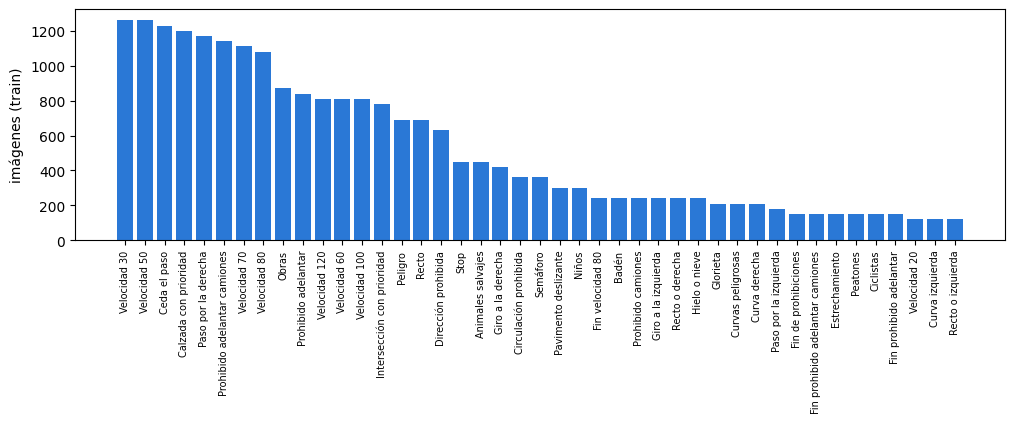

In [ ]:
conteo = tabla[tabla['particion'] == 'train']['etiqueta'].value_counts()
print(f'Desbalanceo: la clase más grande tiene {conteo.max() / conteo.min():.1f} veces más imágenes que la más pequeña')
fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(range(len(conteo)), conteo.values, color='#2a78d6')
ax.set_xticks(range(len(conteo)), clases.loc[conteo.index, 'nombre'], rotation=90, fontsize=7)
ax.set_ylabel('imágenes (train)')
plt.show()

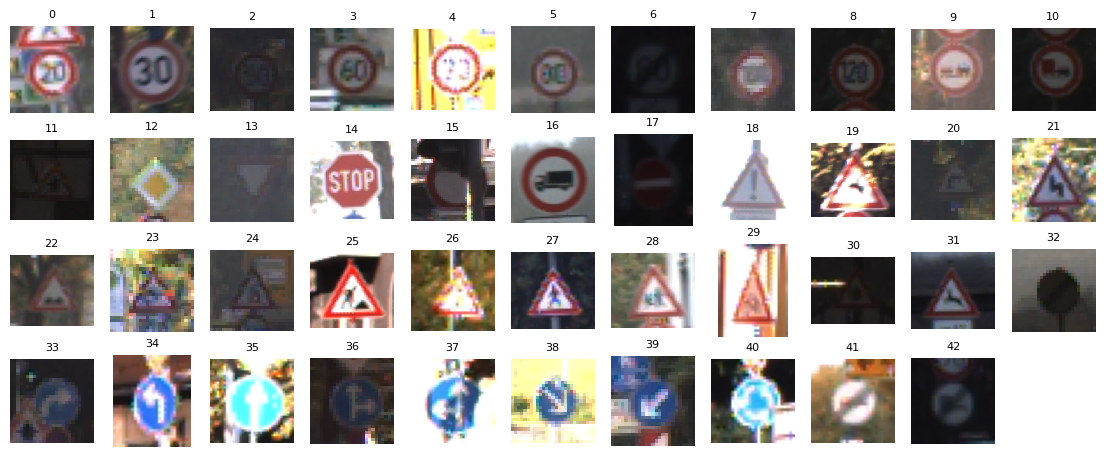

In [ ]:
ejemplos = tabla[tabla['particion'] == 'train'].groupby('etiqueta').first()
fig, axs = plt.subplots(4, 11, figsize=(14, 5.5))
for ax, (et, fila) in zip(axs.flat, ejemplos.iterrows()):
    ax.imshow(Image.open(fila['ruta'])); ax.set_title(et, fontsize=8)
for ax in axs.flat:
    ax.axis('off')
plt.show()

## 3 · Extracción de características

**Teoría:** 3.3 · bloque 7 y 4.2 · bloque 6.

Cada imagen pasa **una vez** por cada modelo y se guarda su vector. Todo lo demás (U3, U4) trabaja con esos vectores, que es muy rápido. Si ya están calculadas, se cargan de `TRABAJO/features`.

In [ ]:
(TRABAJO / 'features').mkdir(exist_ok=True)
FEATS = {}
for nombre in MODELOS:
    fichero = TRABAJO / 'features' / f'{nombre}.pt'
    if fichero.exists() and torch.load(fichero)['rutas'] == tabla['ruta'].tolist():
        FEATS[nombre] = torch.load(fichero)['feats'].numpy()
    else:
        modelo, tf = cargar_modelo(nombre)
        feats = extraer(modelo, tf, tabla['ruta'])
        torch.save({'feats': feats, 'rutas': tabla['ruta'].tolist()}, fichero)
        FEATS[nombre] = feats.numpy()
    print(nombre, FEATS[nombre].shape)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 76.9MB/s]


resnet50 (39270, 2048)
Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 213MB/s]


dinov2_vits14 (39270, 384)


clip_vitb32 (39270, 512)


## 4 · Clasificador lineal (*linear probe*)

**Teoría:** 3.2 · bloque 5 (un buen extractor + un clasificador simple).

Una capa lineal sobre las *features* estandarizadas. Equivale a una regresión logística, pero se entrena en GPU, que es más rápido. Es **la referencia que hay que batir** en U3 y U4.

In [ ]:
y = tabla['etiqueta'].to_numpy()
tr, va, te = [(tabla['particion'] == p).to_numpy() for p in ('train', 'val', 'test')]

resultados, PRED_TEST = [], {}
for nombre, X in FEATS.items():
    X_tr, X_va, X_te = estandarizar(X[tr], X[va], X[te])
    cabeza = entrenar_cabeza(X_tr, y[tr], len(clases))
    PRED_TEST[nombre] = predecir(cabeza, X_te)
    resultados.append({'modelo': nombre, 'particion': 'val', **metricas(y[va], predecir(cabeza, X_va))})
    resultados.append({'modelo': nombre, 'particion': 'test', **metricas(y[te], PRED_TEST[nombre])})
resultados = pd.DataFrame(resultados)
resultados.round(3)

,modelo,particion,accuracy,balanced_acc,macro_f1
0,resnet50,val,0.761,0.666,0.660
1,resnet50,test,0.755,0.639,0.647
2,dinov2_vits14,val,0.721,0.623,0.619
3,dinov2_vits14,test,0.703,0.620,0.630
4,clip_vitb32,val,0.895,0.814,0.814
5,clip_vitb32,test,0.899,0.840,0.849


## 5 · Evaluación

**Teoría:** 3.1 · bloque 1 (¿Cómo medirlo?).

Más allá de la *accuracy*: por clase, por grupo y dónde se confunde el modelo. El modelo se elige con **validación**; el test solo se mira al final.

Mejor modelo en validación: clip_vitb32


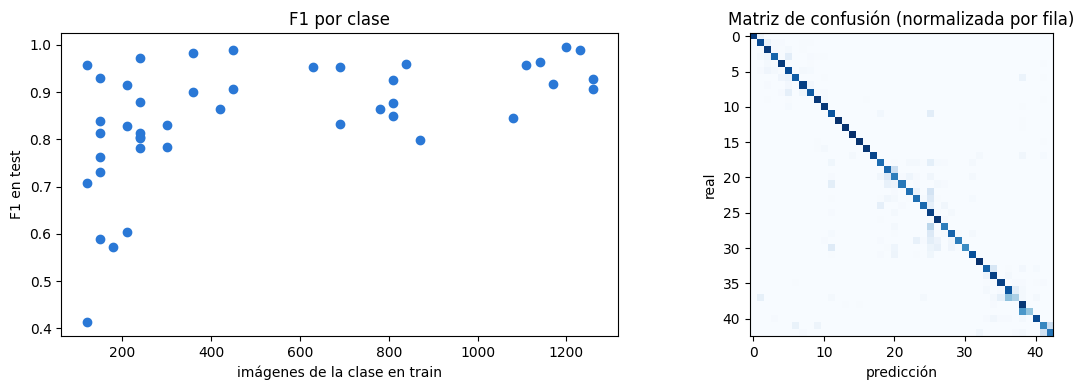

Clases con peor F1: [('Recto o izquierda', 0.41), ('Paso por la izquierda', 0.57), ('Fin prohibido adelantar', 0.59), ('Curva derecha', 0.6), ('Curva izquierda', 0.71)]


In [ ]:
from sklearn.metrics import confusion_matrix

MEJOR = resultados[resultados['particion'] == 'val'].sort_values('macro_f1').iloc[-1]['modelo']
pred = PRED_TEST[MEJOR]
print('Mejor modelo en validación:', MEJOR)

f1_clase = f1_score(y[te], pred, average=None)
n_train = np.bincount(y[tr], minlength=len(clases))
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].scatter(n_train, f1_clase, color='#2a78d6')
axs[0].set_xlabel('imágenes de la clase en train'); axs[0].set_ylabel('F1 en test'); axs[0].set_title('F1 por clase')
axs[1].imshow(confusion_matrix(y[te], pred, normalize='true'), cmap='Blues')
axs[1].set_title('Matriz de confusión (normalizada por fila)'); axs[1].set_xlabel('predicción'); axs[1].set_ylabel('real')
plt.tight_layout(); plt.show()

peores = np.argsort(f1_clase)[:5]
print('Clases con peor F1:', [(clases.loc[c, 'nombre'], round(float(f1_clase[c]), 2)) for c in peores])

In [ ]:
por_grupo = (pd.DataFrame({'grupo': tabla.loc[te, 'grupo'].to_numpy(), 'acierto': y[te] == pred})
             .groupby('grupo')['acierto'].agg(['mean', 'size']).rename(columns={'mean': 'accuracy', 'size': 'n'}))
por_grupo.round(3)

,accuracy,n
grupo,,
fin de restricción,0.806,360
obligación,0.879,1770
peligro,0.823,2790
prioridad,0.991,1680
prohibición,0.959,1860
velocidad,0.904,4170


## 6 · Análisis preliminar

Lo que dicen estos resultados de cara a las unidades siguientes, en el ejemplo de las señales de tráfico:

- **¿Hay datos suficientes?** Sí en conjunto (unas 22 500 imágenes de entrenamiento), pero repartidas en 43 clases y en pistas de unas 30 fotos casi iguales: hay menos variedad de la que parece.
- **¿Están desbalanceados?** Sí: la clase más grande tiene unas 10 veces más imágenes que la más pequeña, y la *balanced accuracy* queda varios puntos por debajo de la *accuracy*. Las clases con peor F1 son de las pequeñas y se confunden con señales parecidas (giros, curvas). Es el primer candidato para U3.
- **¿Qué modelo preentrenado funciona mejor?** CLIP, con diferencia. DINOv2 queda por debajo de ResNet-50: merece la pena entender por qué en U3 (comparar preentrenamientos).
- **¿Hay grupos que funcionen peor?** Las señales de peligro y las de fin de restricción, que son las más parecidas entre sí.
- **¿Hay varios dominios?** No: todo son fotos del mismo tipo. Para U4 habrá que justificar un destino (por ejemplo, niebla o noche, que en un coche sí son cambios realistas).
- **¿Es un tema sensible?** No hay personas ni datos personales. En temas con personas o con salud, decidlo aquí y tenedlo en cuenta en U5.

## 7 · Guardar

La tabla, las clases y las *features* ya están en `TRABAJO`. Guardamos también el resumen.

In [ ]:
resultados.to_csv(TRABAJO / 'resultados_baseline.csv', index=False)
print(sorted(str(p.relative_to(TRABAJO)) for p in TRABAJO.rglob('*') if p.is_file()))

['clases.csv', 'features/clip_vitb32.pt', 'features/dinov2_vits14.pt', 'features/resnet50.pt', 'resultados_baseline.csv', 'tabla.csv']
